# Лабораторна 2

Зниження розмірності, кластеризація та класифікація текстових даних.

Частини 1 і 2 роблю на датасеті з першої лаби - MAGIC Gamma Telescope (10 числових ознак, 2 класи: g - гамма, h - адрон).
Для частини 3 взяв AG News - новини з 4 категорій, залишив 3: World, Sports, Sci/Tech.

In [1]:
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             silhouette_score, adjusted_rand_score)
from wordcloud import WordCloud

## 1. Зниження розмірності та візуалізація

### Дані з лаби 1

In [2]:
cols = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
df = pd.read_csv('../lab1/magic04.data', header=None, names=cols)
df = df.drop_duplicates()
df['class'] = LabelEncoder().fit_transform(df['class'])   # g = 0, h = 1
print(df.shape)
df['class'].value_counts()

(18905, 11)


class
0    12332
1     6573
Name: count, dtype: int64

Обробка така сама як в лабі 1: видалив дублікати, клас перевів в 0/1.

In [3]:
X = df.drop(columns='class')
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

PCA чутливий до масштабу (шукає напрямки з найбільшою дисперсією), тому спочатку StandardScaler, інакше головні компоненти просто повторять ознаки з найбільшими числами (fDist, fLength).

### PCA: скільки компонент залишати

[0.422 0.158 0.101 0.099 0.074 0.066 0.041 0.022 0.016 0.002]
[0.422 0.58  0.681 0.78  0.854 0.92  0.96  0.982 0.998 1.   ]


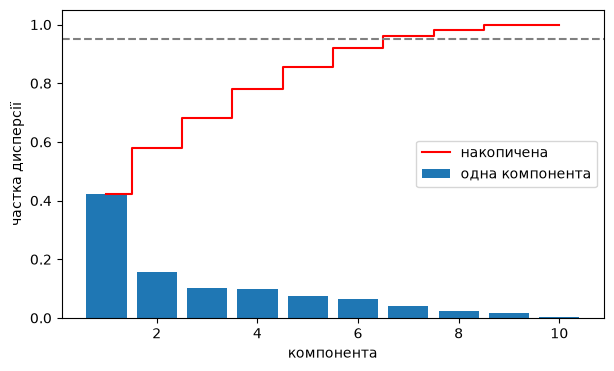

In [4]:
pca_full = PCA().fit(X_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
print(np.round(pca_full.explained_variance_ratio_, 3))
print(np.round(cum, 3))

plt.figure(figsize=(7, 4))
plt.bar(range(1, 11), pca_full.explained_variance_ratio_, label='одна компонента')
plt.step(range(1, 11), cum, where='mid', color='red', label='накопичена')
plt.axhline(0.95, ls='--', color='gray')
plt.xlabel('компонента')
plt.ylabel('частка дисперсії')
plt.legend()
plt.show()

Перша компонента пояснює 42% дисперсії, дві перші - 58%. Щоб зберегти 95% дисперсії, треба 7 компонент з 10. Остання компонента майже нічого не пояснює (0.2%) - це через fConc і fConc1, які корелюють майже на 1 (бачив на heatmap в лабі 1), тобто одна з них майже повністю дублює іншу.

### Класифікація до і після PCA

Беру SVM з найкращими параметрами з лаби 1 (C=10, gamma=0.1), бо він був одним з кращих і його час навчання сильно залежить від кількості ознак.

In [5]:
def run(Xtr, Xte, name):
    m = SVC(C=10, gamma=0.1)
    t = time.time()
    m.fit(Xtr, y_train)
    t = time.time() - t
    acc = accuracy_score(y_test, m.predict(Xte))
    return {'дані': name, 'ознак': Xtr.shape[1], 'accuracy': round(acc, 4), 'час навчання, с': round(t, 2)}

rows = [run(X_train_s, X_test_s, 'без PCA')]
for k in [2, 3, 5, 7]:
    pca = PCA(n_components=k).fit(X_train_s)
    rows.append(run(pca.transform(X_train_s), pca.transform(X_test_s), f'PCA {k}'))

pca95 = PCA(n_components=0.95).fit(X_train_s)
rows.append(run(pca95.transform(X_train_s), pca95.transform(X_test_s), 'PCA 95%'))
res_pca = pd.DataFrame(rows)
res_pca

,дані,ознак,accuracy,"час навчання, с"
0,без PCA,10,0.8748,1.75
1,PCA 2,2,0.7470,3.06
2,PCA 3,3,0.7722,2.54
3,PCA 5,5,0.8261,1.97
4,PCA 7,7,0.8308,1.83
5,PCA 95%,7,0.8308,1.82


Без PCA accuracy 0.875 (як в лабі 1). З 7 компонентами (95% дисперсії) - 0.831, тобто на 4.4 п.п. гірше. З 2-3 компонентами - 0.75-0.77, це вже недалеко від 0.65 (якщо все називати гаммою).

- **Якість:** погіршилась. PCA не дивиться на мітки класів, він залишає напрямки з найбільшою дисперсією, а не ті, що найкраще розділяють класи. Ті 5% дисперсії, які відкинули, як виявилось, містили корисну інформацію для розрізнення гамми і адронів.
- **Кількість ознак:** з 10 до 7 (на 30%) при 95% дисперсії, або до 2 для візуалізації.
- **Час навчання:** не зменшився, навіть трохи виріс (1.75 с -> 1.8-3.1 с). У SVM з RBF ядром час залежить не стільки від кількості ознак, скільки від кількості опорних векторів, а після PCA класи сильніше перекриваються - опорних векторів стає більше.

Тобто для датасету з 10 ознак PCA не потрібен. Він має сенс, коли ознак сотні або тисячі (як у текстах чи зображеннях) і вони сильно корелюють.

### t-SNE в 2D

t-SNE на всіх 19 тис. точок рахується довго, тому беру випадкові 5000 (стратифіковано).

t-SNE, c: 7.1


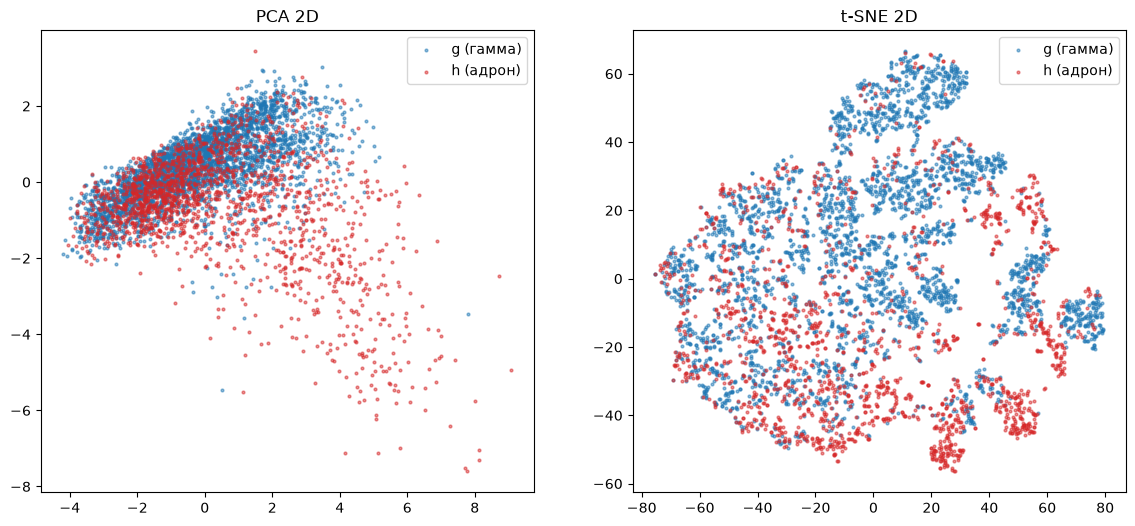

In [6]:
X_s_all = StandardScaler().fit_transform(X)
X_sub, _, y_sub, _ = train_test_split(X_s_all, y, train_size=5000, random_state=42, stratify=y)

t = time.time()
emb = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_sub)
print('t-SNE, c:', round(time.time() - t, 1))

pca2 = PCA(n_components=2).fit_transform(X_sub)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for cls, name, c in [(0, 'g (гамма)', 'tab:blue'), (1, 'h (адрон)', 'tab:red')]:
    ax[0].scatter(pca2[y_sub == cls, 0], pca2[y_sub == cls, 1], s=4, alpha=0.5, c=c, label=name)
    ax[1].scatter(emb[y_sub == cls, 0], emb[y_sub == cls, 1], s=4, alpha=0.5, c=c, label=name)
ax[0].set_title('PCA 2D')
ax[1].set_title('t-SNE 2D')
ax[0].legend(); ax[1].legend()
plt.show()

На PCA 2D класи сильно накладаються, відділяється тільки "хвіст" адронів вниз-вправо (великі довгі події). t-SNE краще зберігає локальну структуру (хто з ким поруч): видно окремі острівці майже тільки з гамми і окремі - майже тільки з адронів, але велика частина точок все одно перемішана.

Це пояснює результати лаби 1: частину подій розрізнити легко, а частина в просторі ознак виглядає однаково, тому accuracy всіх моделей впирається в ~0.87-0.88.

Важливо: в t-SNE відстані між острівцями і їх розміри нічого не означають, сенс має тільки те, які точки є сусідами. Ще t-SNE не можна застосувати до нових даних (немає `transform`), тому для класифікації він не підходить, тільки для візуалізації.

## 2. Кластерний аналіз (K-Means)

Мітки класів тут не використовую, кластеризую тільки ознаки (масштабовані). Мітки беру тільки в кінці щоб порівняти.

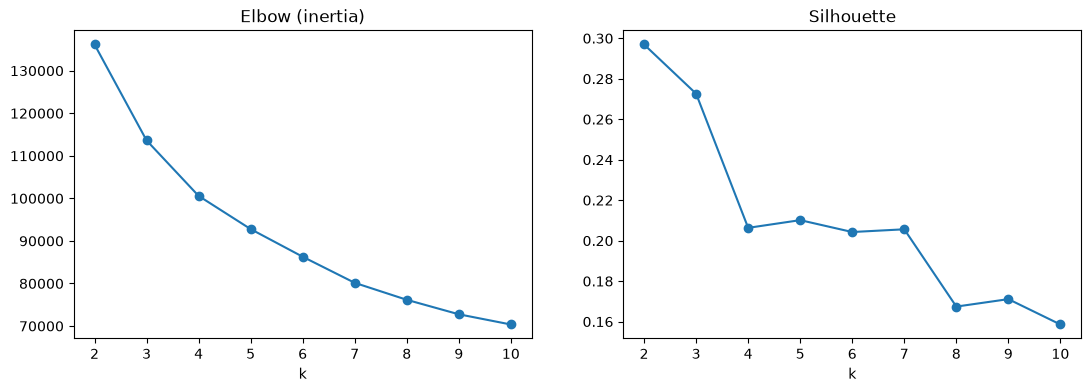

 k  inertia  silhouette
 2 136161.0       0.297
 3 113616.0       0.273
 4 100580.0       0.206
 5  92783.0       0.210
 6  86283.0       0.204
 7  80152.0       0.206
 8  76165.0       0.167
 9  72761.0       0.171
10  70363.0       0.159


In [7]:
X_clu = X_s_all
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_clu, km.labels_, sample_size=5000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(ks, sil, 'o-'); ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
plt.show()
print(pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia), 'silhouette': np.round(sil, 3)}).to_string(index=False))

На графіку Elbow чіткого "ліктя" нема - інерція спадає плавно, найбільший спад на 2->3 і 3->4. Silhouette найбільший при k=2 (0.297), майже такий же при k=3 (0.273), а з k=4 різко падає до ~0.21. Тому доцільно 2 або 3 кластери, далі подивлюсь на обидва.

Сам silhouette невисокий (< 0.3) - кластери нечітко відокремлені один від одного, дані скоріше одна суцільна хмара.

k за silhouette: 2


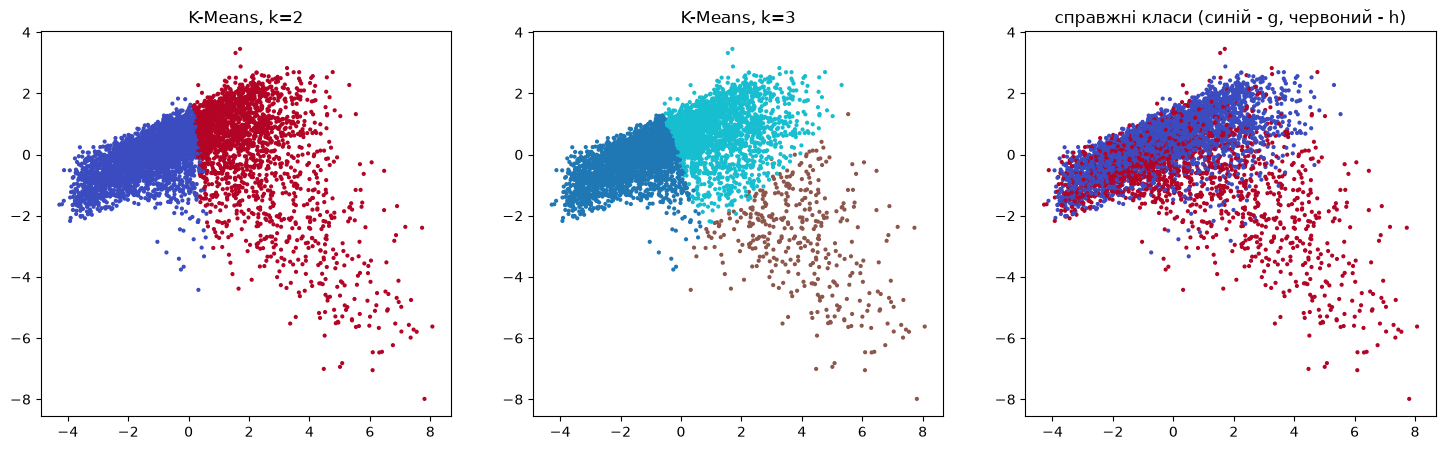

In [8]:
best_k = int(list(ks)[int(np.argmax(sil))])
km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_clu)
print('k за silhouette:', best_k)

idx = np.random.RandomState(42).choice(len(X_clu), 5000, replace=False)
p2 = PCA(n_components=2).fit(X_clu).transform(X_clu[idx])

km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_clu)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(p2[:, 0], p2[:, 1], c=km2.labels_[idx], cmap='coolwarm', s=4)
ax[0].set_title('K-Means, k=2')
ax[1].scatter(p2[:, 0], p2[:, 1], c=km3.labels_[idx], cmap='tab10', s=4)
ax[1].set_title('K-Means, k=3')
ax[2].scatter(p2[:, 0], p2[:, 1], c=y.values[idx], cmap='coolwarm', s=4)
ax[2].set_title('справжні класи (синій - g, червоний - h)')
plt.show()

### Порівняння кластерів з класами

In [9]:
for name, km in [('k=2', km2), ('k=3', km3)]:
    print(name, ' ARI =', round(adjusted_rand_score(y, km.labels_), 3))
    print(pd.crosstab(km.labels_, y, rownames=['кластер'], colnames=['клас']))
    print()

# якщо кожен кластер назвати його більшим класом - яка вийде "точність"
ct = pd.crosstab(km2.labels_, y)
print('k=2, точність якщо кластер = більшість:', round(ct.max(axis=1).sum() / len(y), 3))
print('частка більшого класу (g):', round(y.value_counts(normalize=True).max(), 3))

k=2  ARI = 0.007
клас        0     1
кластер            
0        7506  3694
1        4826  2879

k=3  ARI = 0.069
клас        0     1
кластер            
0        6186  3336
1          55  1311
2        6091  1926

k=2, точність якщо кластер = більшість: 0.652
частка більшого класу (g): 0.652


**k = 2.** ARI = 0.007, тобто практично нуль - кластери з класами не повʼязані. В обох кластерах співвідношення g : h приблизно однакове (2 : 1 і 1.7 : 1), і якщо кожен кластер назвати його більшим класом, виходить 0.652 - рівно частка гамми, тобто не краще, ніж все називати гаммою.

На картинці видно чому: K-Means розрізав хмару навпіл вздовж першої головної компоненти, бо вздовж неї найбільший розкид. Це по суті "розмір/яскравість" події (fSize, fLength, fConc). А гамма від адронів відрізняється в основному кутом fAlpha і формою, і ця різниця "всередині" хмари, а не між її половинами.

**k = 3.** ARI = 0.069, трохи краще: зʼявився маленький кластер (1366 точок), в якому 96% адрони - це той самий "хвіст" великих довгих подій. Але два великі кластери все одно змішані.

**Висновок:** знайдена кластерна структура не відповідає реальним класам. K-Means шукає компактні "кулясті" групи за евклідовою відстанню, а тут класи не утворюють окремих груп - вони перекриваються, і відрізняються кількома ознаками, а не положенням у всьому просторі. Кластеризація знайшла інший поділ (великі/малі події), він теж має сенс, але не той, що потрібен. Для цієї задачі навчання з учителем (лаба 1) працює набагато краще.

## 3. Класифікація текстів

Датасет AG News (https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset) - заголовки і короткі описи новин.
Повний train має 120 тис. новин по 4 класах. Я залишив 3 класи (World, Sports, Sci/Tech), бо Business сильно перетинається з World і Sci/Tech, і взяв по 10 тис. з кожного класу щоб файл був невеликий. Test - офіційний, по 1900 на клас.

In [10]:
train = pd.read_csv('ag_news_3cls_train.csv')
test = pd.read_csv('ag_news_3cls_test.csv')
print(train.shape, test.shape)
print(train['label'].value_counts())
train.head()

(30000, 3) (5700, 3)
label
Sports      10000
World       10000
Sci/Tech    10000
Name: count, dtype: int64


,label,title,description
0,Sports,Ching's Late Goal Rescues U.S. in Soccer World...,"Although the visitors did not get a victory, t..."
1,Sports,"Power in final, but at huge cost",If it #39;s the final of the PACE Canadian Squ...
2,World,British minister and Blair ally Blunkett resigns,LONDON - A Cabinet minister embroiled in the m...
3,Sci/Tech,Vodafone unleashes 3G live! service,Vodafone has flicked the switch for the start ...
4,Sci/Tech,Linux To Ring Up \$35 Billion By 2008,"For a theoretically free operating system, Lin..."


In [11]:
train['text'] = train['title'] + '. ' + train['description']
test['text'] = test['title'] + '. ' + test['description']
train['text'].str.split().str.len().describe()

count    30000.000000
mean        38.107067
std         10.990597
min          8.000000
25%         32.000000
50%         37.000000
75%         43.000000
max        177.000000
Name: text, dtype: float64

Заголовок і опис склеїв в один текст. Тексти короткі - в середньому ~35 слів.

### Передобробка

In [12]:
days = {'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'today', 'yesterday', 'tomorrow'}
stop = set(ENGLISH_STOP_WORDS) | days | {'said', 'says', 'say', 'reuters', 'ap', 'afp', 'new', 'quot', 'lt', 'gt',
                                         'href', 'http', 'www', 'com', 'year', 'years', 'week', 'time'}

def clean(s):
    s = s.lower()
    s = re.sub(r'&[a-z]+;|#\d+;', ' ', s)     # html-сутності типу &lt; #39;
    s = re.sub(r'<[^>]+>', ' ', s)            # теги
    s = re.sub(r'[^a-z\s]', ' ', s)          # пунктуація і цифри
    return ' '.join(w for w in s.split() if w not in stop and len(w) > 2)

train['clean'] = train['text'].apply(clean)
test['clean'] = test['text'].apply(clean)
for i in range(3):
    print(train['text'][i])
    print('->', train['clean'][i])
    print()

Ching's Late Goal Rescues U.S. in Soccer World Cup Qualifier. Although the visitors did not get a victory, the United States is still in a good position after what figured to be the most threatening game of the regional semifinal round.
-> ching late goal rescues soccer world cup qualifier visitors did victory united states good position figured threatening game regional semifinal round

Power in final, but at huge cost. If it #39;s the final of the PACE Canadian Squash Classic, then Jonathon Power must be involved. But it was only with a hard victory that took 91 minutes last night that Power, who beat Anthony Ricketts, will 
-> power final huge cost final pace canadian squash classic jonathon power involved hard victory took minutes night power beat anthony ricketts

British minister and Blair ally Blunkett resigns. LONDON - A Cabinet minister embroiled in the messy fallout of an affair with a married woman resigned on Wednesday, his department said.
-> british minister blair ally bl

Привів до нижнього регістру, прибрав html-залишки (в AG News є `&lt;`, `#39;` і т.д.), пунктуацію, цифри, стоп-слова і слова коротші 3 букв. До стоп-слів додав 'reuters', 'ap', 'afp', 'said'/'says' - вони є майже в кожній новині і нічого не кажуть про тему. Також дні тижня, 'year', 'week', 'time' - в першій версії WordCloud вони були великими у всіх трьох класах одночасно (новини завжди пишуть коли щось сталось), тобто для розрізнення тем вони марні.

### WordCloud по класах

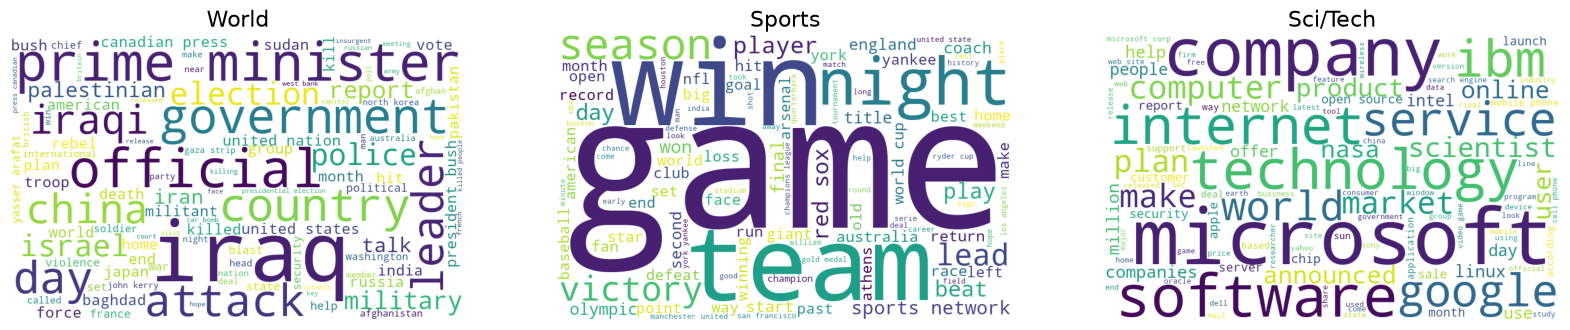

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for i, lab in enumerate(['World', 'Sports', 'Sci/Tech']):
    txt = ' '.join(train.loc[train['label'] == lab, 'clean'])
    wc = WordCloud(width=800, height=500, background_color='white', collocations=True,
                   max_words=100, random_state=42).generate(txt)
    ax[i].imshow(wc)
    ax[i].set_title(lab, fontsize=16)
    ax[i].axis('off')
plt.show()

- **World** - політика і конфлікти: iraq, iraqi, prime minister, government, official, attack, election, military, china, israel, palestinian. Новини 2004 року, тому так багато Іраку.
- **Sports** - game, team, win, season, victory, coach, player, а також конкретні команди і події: red sox, yankee, world cup, athens, olympic (Олімпіада 2004 в Афінах).
- **Sci/Tech** - компанії і технології: microsoft, ibm, google, software, internet, technology, computer, online, а також nasa, scientist.

Словосполучення (collocations=True) теж видно: prime minister, united states, red sox, world cup, open source, microsoft corp. Характерні слова в класах майже не перетинаються, тому класифікація має бути нескладною. Невеликий перетин є - наприклад 'world' зустрічається і в Sports (world cup), і в Sci/Tech, а 'company', 'market' в Sci/Tech повʼязані з бізнесом.

### TF-IDF і класифікація

In [14]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
Xtr = tfidf.fit_transform(train['clean'])
Xte = tfidf.transform(test['clean'])
print(Xtr.shape)

(30000, 91544)


Біграми теж беру (ngram_range=(1, 2)), щоб словосполучення типу 'world cup' чи 'prime minister' були окремими ознаками. min_df=2 відкидає слова, які є тільки в одному тексті.

In [15]:
models = {
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(C=10, max_iter=2000),
}
pred = {}
for name, m in models.items():
    t = time.time()
    m.fit(Xtr, train['label'])
    pred[name] = m.predict(Xte)
    print(name, 'accuracy =', round(accuracy_score(test['label'], pred[name]), 4), ' час', round(time.time() - t, 1), 'с')

Naive Bayes accuracy = 0.9554  час 0.0 с


Logistic Regression accuracy = 0.9504  час 0.9 с


Naive Bayes
              precision    recall  f1-score   support

       World      0.958     0.921     0.939      1900
      Sports      0.959     0.983     0.971      1900
    Sci/Tech      0.949     0.963     0.956      1900

    accuracy                          0.955      5700
   macro avg      0.955     0.955     0.955      5700
weighted avg      0.955     0.955     0.955      5700

Logistic Regression
              precision    recall  f1-score   support

       World      0.943     0.929     0.936      1900
      Sports      0.953     0.975     0.964      1900
    Sci/Tech      0.954     0.947     0.951      1900

    accuracy                          0.950      5700
   macro avg      0.950     0.950     0.950      5700
weighted avg      0.950     0.950     0.950      5700



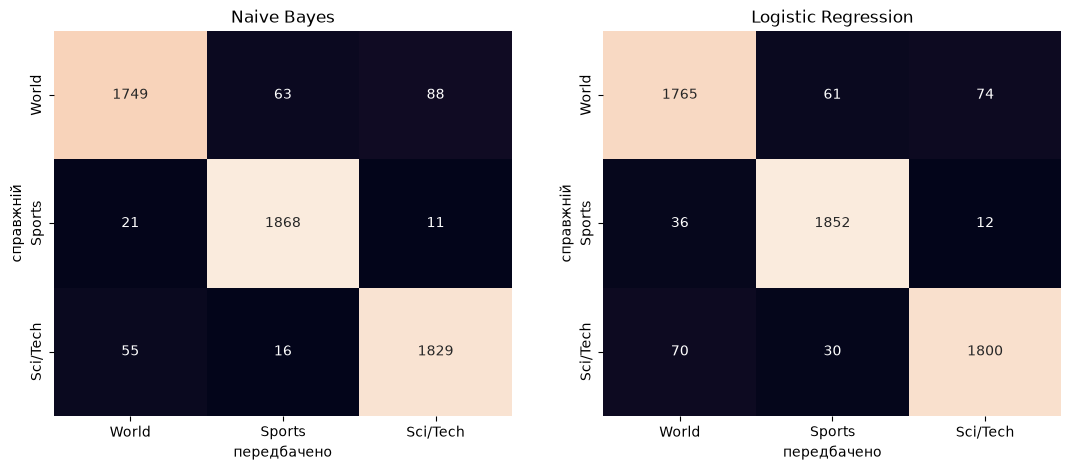

In [16]:
labels = ['World', 'Sports', 'Sci/Tech']
for name in pred:
    print(name)
    print(classification_report(test['label'], pred[name], labels=labels, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, name in enumerate(pred):
    sns.heatmap(confusion_matrix(test['label'], pred[name], labels=labels), annot=True, fmt='d',
                xticklabels=labels, yticklabels=labels, cbar=False, ax=ax[i])
    ax[i].set_title(name); ax[i].set_xlabel('передбачено'); ax[i].set_ylabel('справжній')
plt.show()

In [17]:
lr = models['Logistic Regression']
feat = np.array(tfidf.get_feature_names_out())
for i, cls in enumerate(lr.classes_):
    top = np.argsort(lr.coef_[i])[-10:][::-1]
    print(cls, ':', ', '.join(feat[top]))

Sci/Tech : microsoft, internet, software, space, nasa, online, web, computer, ibm, wireless
Sports : coach, cup, team, sports, season, league, stadium, olympic, manager, club
World : iraq, president, nuclear, iraqi, government, troops, iran, minister, election, israel


Обидві моделі дають близько 95%: Naive Bayes 0.955, Logistic Regression 0.950. NB навіть трохи кращий і вчиться миттєво - для TF-IDF текстів це очікувано, бо ознак дуже багато (95 тис.), а кожен текст короткий.

- Найлегший клас - **Sports** (f1 0.96-0.97): спортивну лексику важко сплутати.
- Найважчий - **World** (recall 0.92-0.93): найбільше помилок World -> Sci/Tech (74-88) і Sci/Tech -> World (55-70).

Найважливіші слова в Logistic Regression (найбільші коефіцієнти) майже збігаються з WordCloud: iraq, president, nuclear для World; coach, cup, team для Sports; microsoft, internet, software для Sci/Tech. Тобто модель вчиться саме на тематичних словах.

In [18]:
errs = test[(pred['Logistic Regression'] != test['label'])].copy()
errs['pred'] = pred['Logistic Regression'][errs.index]
errs[['label', 'pred', 'text']].head(8)

,label,pred,text
2,Sci/Tech,World,Prediction Unit Helps Forecast Wildfires (AP)....
7,Sci/Tech,World,E-mail scam targets police chief. Wiltshire Po...
74,World,Sports,Live: Olympics day four. Richard Faulds and St...
109,Sports,World,Security scare as intruder dives in. A CANADIA...
136,World,Sci/Tech,"Google Lowers Its IPO Price Range. SAN JOSE, C..."
137,World,Sci/Tech,"Future Doctors, Crossing Borders. Students at ..."
168,World,Sci/Tech,Stock Prices Climb Ahead of Google IPO. NEW YO...
219,Sci/Tech,World,"Atlantis ""Evidence"" Found in Spain, Ireland. I..."


Помилки здебільшого на новинах, які реально стосуються двох тем: IPO Google (бізнес/технології, але в датасеті позначено як World), прогноз лісових пожеж (наука, але модель бачить 'fire', 'officials' і вважає це World), Олімпіада з позначкою World. Частину таких міток навіть людина поставила б інакше, тому 95% - це вже близько до межі для цього датасету.

## Висновок

1. **PCA** на MAGIC дозволив зменшити кількість ознак з 10 до 7 при 95% дисперсії, але accuracy SVM впала з 0.875 до 0.831, а час навчання не зменшився. PCA не враховує мітки класів, тому відкинуті компоненти можуть бути корисними для класифікації. Для 10 ознак він не потрібен.
2. **t-SNE** показав, що частина подій утворює "чисті" групи гамми чи адронів, а частина сильно перемішана - це пояснює стелю ~0.88 accuracy з лаби 1.
3. **K-Means** (k = 2-3 за silhouette) знайшов поділ на великі і малі події, а не на гамму і адрони: ARI 0.007 для k=2. Кластери - не те саме, що класи, і тут вони майже не повʼязані, бо класи перекриваються в просторі ознак.
4. **Тексти** AG News (3 класи): після очистки і TF-IDF з біграмами Naive Bayes дав 0.955, Logistic Regression 0.950. WordCloud і коефіцієнти моделі показують ті самі тематичні слова. Помилки в основному між World і Sci/Tech на новинах, що стосуються обох тем.